# AI6124 Group 1 — LSTM-Encoded Fuzzy Local Experts for SRT

**Zou Runze (Ryan) · Ngeow Shan Yong Destin**  
**Final course Notebook, 4 November 2026.**

This single Notebook contains the method, code entry points, chronological data checks, development and frozen final results, interpretation, trading simulation, literature comparison and conclusion. It reads the already saved final predictions; rerunning these cells does not refit a model or select settings on the final holdout. Protocol v1.2 is in `docs/experiment_protocol_lstm_fuzzy_local_experts.md`.

**Research question:** Can an LSTM learn three features from recent SRT/SORA/STI data that support a two-rule fuzzy mixture of local experts for next-day raw SRT return prediction?

## Literature review and result comparison

**Status:** Updated after the frozen 4 November 2026 final evaluation. This section is included in the single course Notebook.

## Method lineage and taxonomy

The proposed model combines two families of methods. An LSTM handles an ordered, multivariate history; a Takagi–Sugeno-style fuzzy layer combines simple local return models. The distinction matters because the LSTM's hidden features are learned from the entire 20-day sequence, while the fuzzy layer receives only a three-dimensional summary at a single forecast time.

1. **Local fuzzy models (1985).** Takagi and Sugeno described fuzzy antecedents whose consequents are local input–output models. This supplies the basic form used here: rule strength times local numerical prediction, followed by aggregation. Our two affine experts are a deliberately small version of that idea, with Gaussian membership functions over learned rather than hand-selected inputs. [Original paper](https://doi.org/10.1109/TSMC.1985.6313399).
2. **Trainable neuro-fuzzy inference (1993).** Jang's ANFIS placed fuzzy inference in an adaptive-network framework and showed how rule parameters could be learned from examples. It is relevant as the classical neuro-fuzzy alternative, but a direct ANFIS on all `20 days × 6 variables` would not express the intended sequential encoder and could make the rule space unnecessarily large. Our LSTM first reduces history to three learned inputs, and all parts are trained jointly by backpropagation. [Original paper](https://doi.org/10.1109/21.256541).
3. **Recurrent sequence representation (1997).** Hochreiter and Schmidhuber introduced LSTM to make learning longer temporal dependencies easier than in conventional recurrent networks. In this project the LSTM is an encoder, and an ordinary LSTM with a scalar return head is the directly relevant benchmark. The benchmark and hybrid receive identical information, so their difference isolates the value of the prediction head more clearly than comparing different datasets or look-back periods. [Original paper](https://doi.org/10.1162/neco.1997.9.8.1735).
4. **Deep sequence encoder plus fuzzy local forecasting (2025).** Ožbot, Škrjanc and Štruc's *Fuzzformer* combines an LSTM, multi-head temporal attention, learned low-dimensional representations, Gaussian fuzzy rules and ARIX local models for multi-horizon S&P 500 forecasting. Their study motivates letting a sequence model learn fuzzy-system inputs. Their paper also uses clustering and rule-separation objectives to support interpretable local models. The present course design removes attention, uses one next-day SRT ETF return, two diagonal-Gaussian rules, two affine experts, and one ordinary MSE objective. It should therefore be described as an **adaptation**, not a reproduction or a claim to obtain the paper's results. [Original paper](https://arxiv.org/html/2510.00960v1).

| Family | Uses time ordering? | Local fuzzy rules? | Role in this project |
| --- | --- | --- | --- |
| No-change return predictor | No learned sequence model | No | Noise-resistant reference for daily ETF returns |
| Ordinary LSTM | Yes | No | Main machine-learning benchmark |
| LSTM → 3D → linear head | Yes | No | Controls for representation compression |
| Classical ANFIS / Takagi–Sugeno-style models | Usually use a fixed-size input vector | Yes | Historical method family; explains rule/consequent form |
| Fuzzformer | Yes, with attention | Yes, with ARIX local models | Recent architecture that motivates the hybrid |
| Our LSTM → 3D → two fuzzy affine experts | Yes | Yes | Small course adaptation on SRT and published local market data |

## Why this adaptation is testable

The first hypothesis is about **forecasting**, not guaranteed superiority: `Fuzzy2` might lower the next-day raw-return RMSE relative to the same-input `LSTM32` or `LSTM3`. The `LSTM3` control is necessary because a better result could come from forcing a compact representation, independently of fuzzy rules. The second hypothesis is about **local specialization**: rule weights and expert outputs might vary meaningfully across observed past-volatility or past-trend conditions. If one rule dominates or both experts predict almost the same return, the intended specialization has not appeared, even if the forecast error is good.

Input-source ablations ask whether adding published SORA and STI improves the SRT forecast beyond SRT history alone. This is a data question, not evidence that either input causes ETF price movements. SORA is aligned by its publication time; the Monetary Authority of Singapore says the rate for a business day is published at 9:00 on the next business day. [MAS publication policy](https://www.mas.gov.sg/monetary-policy/SORA).

The Fuzzformer paper reports experiments on a different market, prediction horizon, target definition, normalization and architecture. Its numeric RMSE values cannot be placed in our result table as a direct head-to-head benchmark. We can compare **method design and observed strengths/limitations** in prose, while our own ordinary LSTM supplies the numerical benchmark on the identical SRT folds.

## Observed result versus recent research

The cited Fuzzformer study uses S&P 500 **multi-horizon price forecasting** with an LSTM, temporal multi-head attention, low-dimensional latent spaces, 16 Gaussian rules and ARIX local models. Its training includes a winner-takes-all local objective and clustering, overlap and balance terms. Its reported test RMSE is broadly comparable to its ARIMA references and lower than its tested LSTM configurations in the reported horizons. The authors also show one decomposed forecast. These are the **paper's observations on its own task**; they do not imply that our two-rule adaptation will reproduce them. [Fuzzformer methods and experiments](https://arxiv.org/html/2510.00960v1).

Our study removes attention and ARIX, fixes two diagonal-Gaussian rules with simple centers, and trains all components using one global MSE objective on **one-day SRT ETF raw returns**. Development RMSE was 0.009489 for `Fuzzy2`, above the 0.009431 unchanged-price reference and the 0.009473 compressed `LSTM3` control. On the one frozen final period, `Fuzzy2` reached RMSE 0.006349 versus 0.006384 for ordinary `LSTM32` and 0.006377 for `Z0`. Its final MAE was worse than `Z0`, and non-Gaussian `Gate2` was close at RMSE 0.006353. These differences are small and metric-dependent; no cross-dataset numerical ranking against Fuzzformer is valid. Source-group differences were similarly small, and the seed-11 `K=3` diagnostic worsened development RMSE.

The mechanism result is more important than the small error ordering. Final `Fuzzy2` maximum rule weights average only about 0.51–0.56, with no day above 0.8; one rule has no test case above its training-defined 75th-percentile activation cut in one seed. The weights and affine contributions explain the model's arithmetic, but the data do not give them stable economic labels. The simplified architecture and global loss may help explain the weak specialization, although this is a **hypothesis**, not a causal attribution established by our ablations. A closer test would preregister a local expert objective or rule-separation term and evaluate it on new periods without replacing this frozen result.

The trading application further distinguishes predictive fit from decision value. The untuned `Fuzzy2` policy ends at 0.999 of initial wealth after 10-bps single-side costs, versus 1.000 for cash, although it exceeds losing always-long and momentum controls in this down test period. Two of three seeds never trade; the model's near-zero, mostly negative predictions explain much of this pattern. This does not establish profitable timing. The primary target is close-to-close while execution is next-open to following-open, and one open quote is unavailable. Price-only and issuer-checked gross-distribution ledgers are reported separately.

## Application areas and theoretical questions

Sequence-to-fuzzy models are plausible when ordered inputs interact with a small number of local response patterns: financial returns, energy demand, industrial process control and other sensor streams. Their transparency should be tested with activation coverage, locally matched errors, stable rule identities and decision outcomes rather than inferred from the presence of fuzzy terminology alone.

Three research questions follow from this experiment. **First**, what local loss or separation constraint improves expert specialization without increasing forecast error or creating empty rules? **Second**, can a learned latent space preserve rule meaning across seeds and rolling refits, or do centers need anchored observable variables? **Third**, how should a rule system adapt to concept drift while keeping its explanations stable and auditable? These questions require new preregistered periods or instruments; the present final holdout cannot be reused for model selection.

A non-financial follow-up could predict next-day building electricity demand from 20 days of load, temperature and occupancy schedules. The LSTM would encode the sequence; a small fuzzy head could represent differing demand responses during occupied and unoccupied conditions. Compare it with a same-input LSTM, compressed latent head and non-Gaussian mixture on chronological future weeks. Test both forecast error and whether high-activation rules consistently reduce local error in independently measured occupancy regimes. This would check semantic usefulness more directly than merely plotting membership weights.

## Bibliography for the final Notebook

- Takagi, T., & Sugeno, M. (1985). *Fuzzy identification of systems and its applications to modeling and control*. IEEE Transactions on Systems, Man, and Cybernetics, SMC-15(1), 116–132. https://doi.org/10.1109/TSMC.1985.6313399
- Jang, J.-S. R. (1993). *ANFIS: Adaptive-network-based fuzzy inference system*. IEEE Transactions on Systems, Man, and Cybernetics, 23(3), 665–685. https://doi.org/10.1109/21.256541
- Hochreiter, S., & Schmidhuber, J. (1997). *Long Short-Term Memory*. Neural Computation, 9(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735
- Ožbot, M., Škrjanc, I., & Štruc, V. (2025). *A Neuro-Fuzzy System for Interpretable Long-Term Stock Market Forecasting*. arXiv:2510.00960v1. https://arxiv.org/html/2510.00960v1
- Ang, K. K. (2026). *AI6124 — Week 8: Neural in Neuro-Fuzzy Systems*. Course lecture PDF supplied to the class.

## Data and information timing

The target is the SGD counter of the CSOP iEdge S-REIT Leaders Index ETF (`SRT.SI`). The primary label is the next-trading-day **raw close-to-close log return**. Each forecast uses the latest 20 SRT trading-day feature rows available after the forecast day's close. SORA is aligned by **publication date**. The saved 28 October snapshot combines SRT, STI and MAS SORA; its raw responses and source hashes are retained in `data/`. The 2025-10-24 SRT close was repaired with a documented second source; its open remains unavailable.

We use three expanding forward-time validation folds, followed by an untouched final holdout. No scaler is fitted on validation or test rows. `src/project_eval.py` provides the shared split and scoring contract.

In [1]:
from pathlib import Path
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

project_root = next(
    (candidate for candidate in (Path.cwd(), Path.cwd().parent)
     if (candidate / "data" / "source_manifest.json").exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Open this Notebook from the project root or docs/ directory")
sys.path.insert(0, str(project_root))
os.chdir(project_root)

from src.project_eval import Dataset, FEATURE_GROUPS, VALIDATION_FOLDS

subprocess.run([sys.executable, "data/verify_dataset.py"], check=True)
data = Dataset()
print("X shape:", data.x.shape)
print("Features:", data.features)

X shape: (1182, 20, 6)
Features: ('srt_log_return_raw', 'srt_momentum_5', 'srt_volatility_20', 'sti_log_return_asof', 'sora_rate_pct_asof', 'sora_change_20_publications_pp')


In [2]:
fold_summary = []
for fold in (*VALIDATION_FOLDS, "final_holdout"):
    role = "test" if fold == "final_holdout" else "validation"
    train_ids, eval_ids = data.ids(fold, "train"), data.ids(fold, role)
    fold_summary.append({
        "fold": fold,
        "train_windows": len(train_ids),
        "eval_windows": len(eval_ids),
        "first_eval_target": data.index.loc[eval_ids[0], "target_date"].date(),
        "last_eval_target": data.index.loc[eval_ids[-1], "target_date"].date(),
    })
display(pd.DataFrame(fold_summary))

,fold,train_windows,eval_windows,first_eval_target,last_eval_target
0,validation_1,553,126,2024-04-01,2024-09-30
1,validation_2,679,124,2024-10-01,2025-03-28
2,validation_3,803,128,2025-04-01,2025-09-30
3,final_holdout,931,251,2025-10-01,2026-09-30


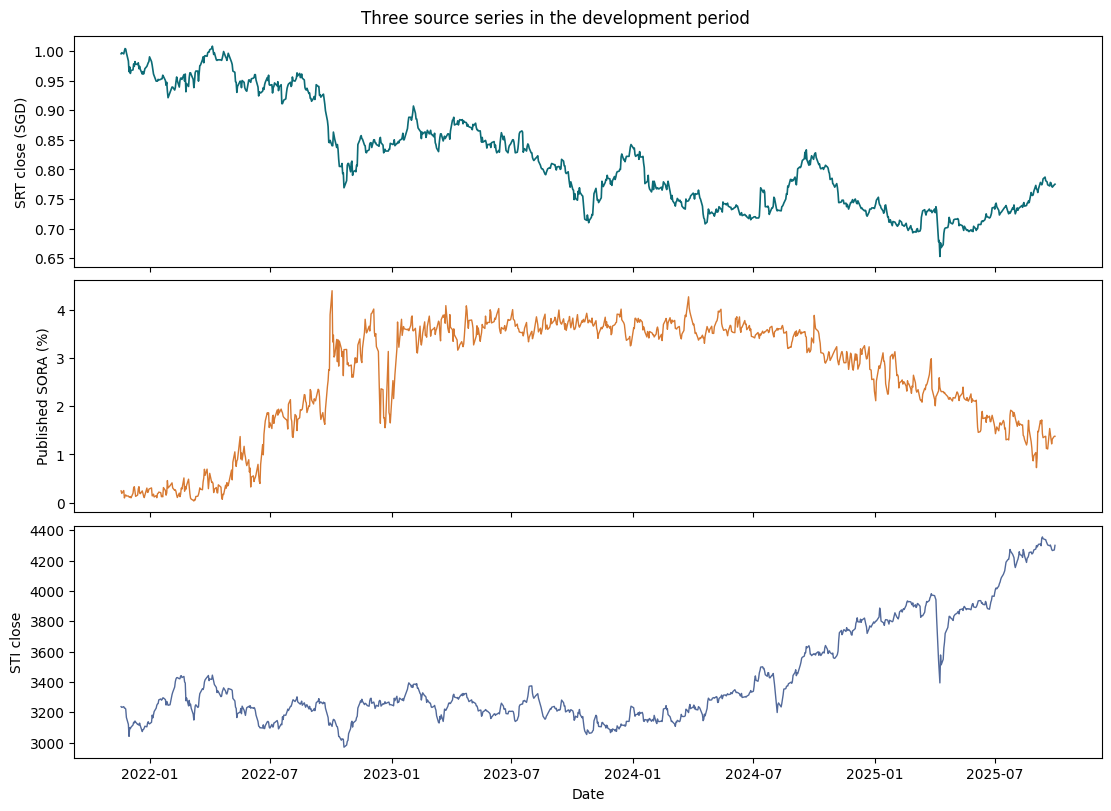

In [3]:
daily = data.daily.loc[data.daily.date <= pd.Timestamp("2025-09-30")].copy()
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, constrained_layout=True)
axes[0].plot(daily.date, daily.srt_close, color="#0c6b76", linewidth=1.2)
axes[0].set_ylabel("SRT close (SGD)")
axes[1].plot(daily.date, daily.sora_rate_pct_asof, color="#d77931", linewidth=1.0)
axes[1].set_ylabel("Published SORA (%)")
axes[2].plot(daily.date, daily.sti_close_asof, color="#52699a", linewidth=1.0)
axes[2].set_ylabel("STI close")
axes[2].set_xlabel("Date")
fig.suptitle("Three source series in the development period")
plt.show()

## Pretest data diagnostics

Inspect SRT close and daily log returns only through the last pretest target. Differencing removes much of the price-level trend but does not guarantee stationary returns or constant volatility. The missing-open date below comes from source-audit metadata; no final-holdout return pattern is plotted or used to revise the model.

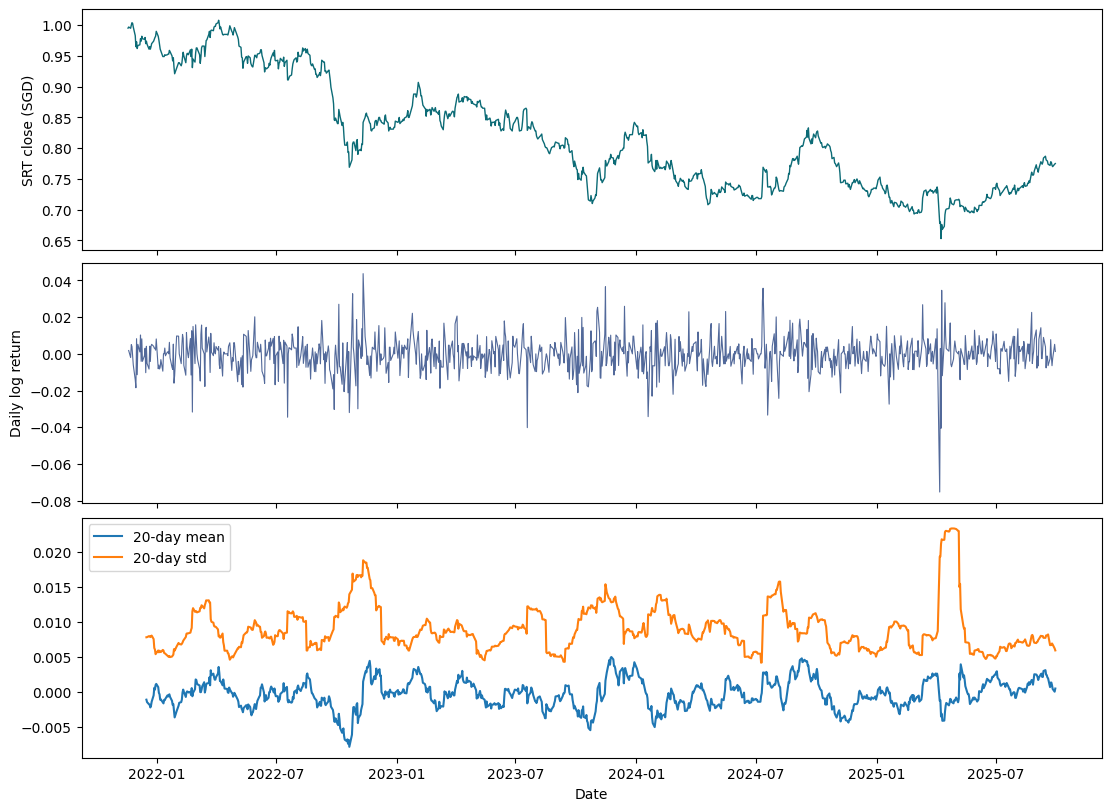

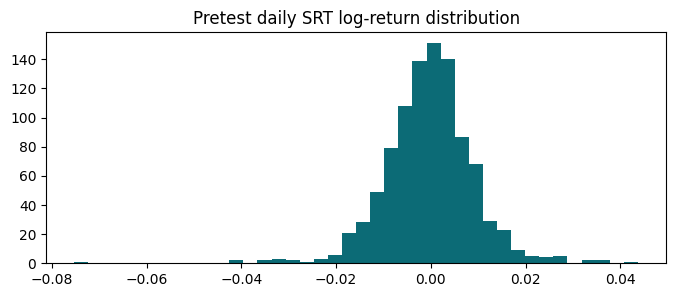

Pretest rows: 971 zero returns: 80 zero fraction: 0.0825
Missing SRT opens in frozen snapshot (date metadata only): [datetime.date(2025, 10, 24)]


In [4]:
pretest_end = data.index.loc[data.ids("final_holdout", "train")[-1], "target_date"]
pretest = data.daily.loc[data.daily.date <= pretest_end, ["date", "srt_close", "srt_open"]].copy()
pretest["log_return"] = np.log(pretest.srt_close).diff()
pretest["rolling_mean_20"] = pretest.log_return.rolling(20).mean()
pretest["rolling_std_20"] = pretest.log_return.rolling(20).std()
diagnostic_dir = Path("output/runs/tmp/phase1_smoke")
diagnostic_dir.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, constrained_layout=True)
axes[0].plot(pretest.date, pretest.srt_close, linewidth=1, color="#0c6b76")
axes[0].set_ylabel("SRT close (SGD)")
axes[1].plot(pretest.date, pretest.log_return, linewidth=.8, color="#52699a")
axes[1].set_ylabel("Daily log return")
axes[2].plot(pretest.date, pretest.rolling_mean_20, label="20-day mean")
axes[2].plot(pretest.date, pretest.rolling_std_20, label="20-day std")
axes[2].legend()
axes[2].set_xlabel("Date")
fig.savefig(diagnostic_dir / "pretest_price_return_rolling.png", dpi=150)
plt.show()
returns = pretest.log_return.dropna()
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(returns, bins=40, color="#0c6b76")
ax.set_title("Pretest daily SRT log-return distribution")
fig.savefig(diagnostic_dir / "pretest_return_distribution.png", dpi=150)
plt.show()
print("Pretest rows:", len(pretest), "zero returns:", int(returns.eq(0).sum()),
      "zero fraction:", round(float(returns.eq(0).mean()), 4))
print("Missing SRT opens in frozen snapshot (date metadata only):",
      data.daily.loc[data.daily.srt_open.isna(), "date"].dt.date.tolist())

## Models and benchmark

- `Z0`: predict zero next-day return (unchanged closing price).
- `LSTM32`: one-layer, 32-hidden-unit LSTM with a scalar return head.
- `LSTM3`: the same encoder with a three-dimensional `tanh` projection and scalar linear head.
- `Fuzzy2`: the same encoder and projection, then two diagonal Gaussian rules and two affine return experts.

The fuzzy system receives only the three learned latent values, not a flattened 20 × 6 input. `Fuzzy2` predicts a rule-weighted return. `Gate2` is the predeclared small non-Gaussian two-expert control. Implementations are in `src/models.py`; the inner-stopping/outer-refit runner is `src/train.py`. The encoder, fuzzy weights and experts are trained only on each fold's training rows; outer validation rows are used only for evaluation.

In [5]:
# Example of the shared train-only scaling and inner stopping split.
inner = data.prepare("validation_1", "all", inner_stop=True)
outer = data.prepare("validation_1", "all", inner_stop=False)
print("Inner train / stopping:", inner.x_train.shape, inner.x_eval.shape)
print("Outer refit / evaluation:", outer.x_train.shape, outer.x_eval.shape)
print("Outer train scaled target mean:", round(float(outer.y_train.mean()), 6))

Inner train / stopping: (470, 20, 6) (83, 20, 6)
Outer refit / evaluation: (553, 20, 6) (126, 20, 6)
Outer train scaled target mean: 0.0


## No-change baseline on the three development folds

The no-change predictor needs no fitting. The code below shows its three development folds; the frozen final comparison appears later. Directional accuracy excludes zero true returns; the majority-direction reference is learned from each fold's training labels.

In [6]:
zero_predictions = data.zero_predictions()
zero_scores = data.forecast_scores(zero_predictions)
zero_pooled = data.pooled_validation_scores(zero_predictions)
display(zero_scores[[
    "fold", "n", "return_rmse", "return_mae", "price_rmse_sgd",
    "direction_n", "zero_actual_n", "train_majority_accuracy"
]])
display(zero_pooled)

,fold,n,return_rmse,return_mae,price_rmse_sgd,direction_n,zero_actual_n,train_majority_accuracy
0,validation_1,126,0.009828,0.006887,0.007442,110,16,0.500000
1,validation_2,124,0.007270,0.005421,0.005370,111,13,0.549550
2,validation_3,128,0.010787,0.006544,0.007623,122,6,0.434426


,model_id,source_group,rule_count,seed,n,return_rmse,return_mae,price_rmse_sgd,price_mae_sgd,direction_n,zero_actual_n,direction_accuracy
0,Z0,all,0,0,378,0.009431,0.00629,0.006899,0.004651,343,35,0.0


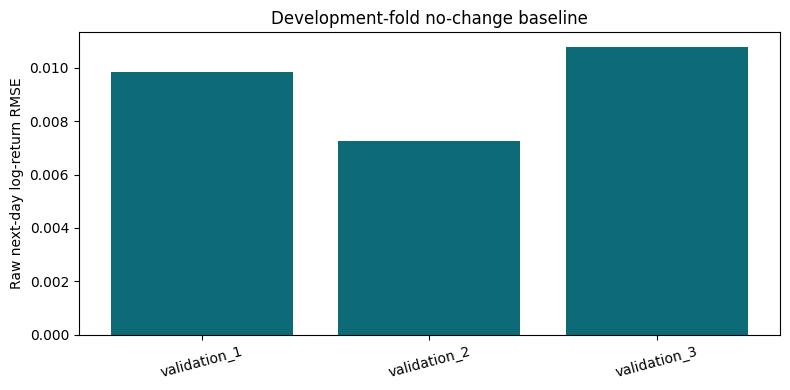

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(zero_scores.fold, zero_scores.return_rmse, color="#0c6b76")
ax.set_ylabel("Raw next-day log-return RMSE")
ax.set_title("Development-fold no-change baseline")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## Trained-model predictions and result analysis

The development runner exports complete outer-validation predictions, combined at `output/development/predictions.csv`, with these columns:

`model_id,source_group,rule_count,fold,seed,window_id,y_pred`

`y_pred` must be in **raw log-return units**, after inverse target scaling. The evaluator validates the full seven-column key and fuzzy case/rule diagnostics. Do not infer that a rule is a particular market regime from its numeric label.

In [8]:
prediction_file = Path("output/development/predictions.csv")
model_predictions = None
if prediction_file.exists():
    model_predictions = pd.read_csv(prediction_file)
    model_scores = data.forecast_scores(model_predictions)
    model_pooled = data.pooled_validation_scores(model_predictions)
    display(model_scores.sort_values(["model_id", "source_group", "rule_count", "fold", "seed"]))
    display(model_pooled.sort_values("return_rmse"))
    if {"Fuzzy2", "LSTM32"} <= set(model_predictions.model_id):
        display(data.paired_validation_rmse_difference(model_predictions))
else:
    print(f"Awaiting trained-model predictions: {prediction_file}")

,model_id,source_group,rule_count,fold,seed,n,return_rmse,return_mae,price_rmse_sgd,price_mae_sgd,direction_n,zero_actual_n,direction_accuracy,train_majority_direction,train_majority_accuracy
0,Fuzzy2,all,2,validation_1,11,126,0.009850,0.006931,0.007458,0.005239,110,16,0.554545,-1,0.500000
1,Fuzzy2,all,2,validation_1,23,126,0.009867,0.006959,0.007473,0.005259,110,16,0.554545,-1,0.500000
2,Fuzzy2,all,2,validation_1,37,126,0.009897,0.006964,0.007493,0.005263,110,16,0.490909,-1,0.500000
3,Fuzzy2,all,2,validation_2,11,124,0.007285,0.005457,0.005376,0.004040,111,13,0.513514,-1,0.549550
4,Fuzzy2,all,2,validation_2,23,124,0.007349,0.005512,0.005417,0.004077,111,13,0.522523,-1,0.549550
5,Fuzzy2,all,2,validation_2,37,124,0.007224,0.005423,0.005332,0.004015,111,13,0.549550,-1,0.549550
6,Fuzzy2,all,2,validation_3,11,128,0.010880,0.006700,0.007691,0.004829,122,6,0.434426,-1,0.434426
7,Fuzzy2,all,2,validation_3,23,128,0.010921,0.006783,0.007725,0.004888,122,6,0.434426,-1,0.434426
8,Fuzzy2,all,2,validation_3,37,128,0.010862,0.006671,0.007680,0.004809,122,6,0.442623,-1,0.434426
9,Fuzzy2,srt,2,validation_1,11,126,0.009892,0.006965,0.007491,0.005263,110,16,0.500000,-1,0.500000


,model_id,source_group,rule_count,seed,n,return_rmse,return_mae,price_rmse_sgd,price_mae_sgd,direction_n,zero_actual_n,direction_accuracy
12,Gate2,all,0,37,378,0.009436,0.006330,0.006905,0.004680,343,35,0.489796
14,LSTM3,all,0,23,378,0.009445,0.006368,0.006910,0.004706,343,35,0.513120
16,LSTM32,all,0,11,378,0.009457,0.006316,0.006917,0.004669,343,35,0.501458
10,Gate2,all,0,11,378,0.009458,0.006338,0.006921,0.004685,343,35,0.501458
6,Fuzzy2,srt_sora,2,11,378,0.009469,0.006351,0.006929,0.004695,343,35,0.475219
2,Fuzzy2,all,2,37,378,0.009472,0.006359,0.006929,0.004700,343,35,0.492711
7,Fuzzy2,srt_sora,2,23,378,0.009473,0.006400,0.006930,0.004728,343,35,0.516035
11,Gate2,all,0,23,378,0.009475,0.006392,0.006937,0.004726,343,35,0.486880
4,Fuzzy2,srt,2,23,378,0.009477,0.006377,0.006932,0.004711,343,35,0.516035
0,Fuzzy2,all,2,11,378,0.009478,0.006370,0.006932,0.004707,343,35,0.498542


,challenger,benchmark,source_group,seed,n,challenger_rmse,benchmark_rmse,delta_rmse,delta_mae
0,Fuzzy2,LSTM32,all,11,378,0.009478,0.009457,0.000021,0.000053
1,Fuzzy2,LSTM32,all,23,378,0.009516,0.009677,-0.000161,-0.000171
2,Fuzzy2,LSTM32,all,37,378,0.009472,0.009736,-0.000264,-0.000283


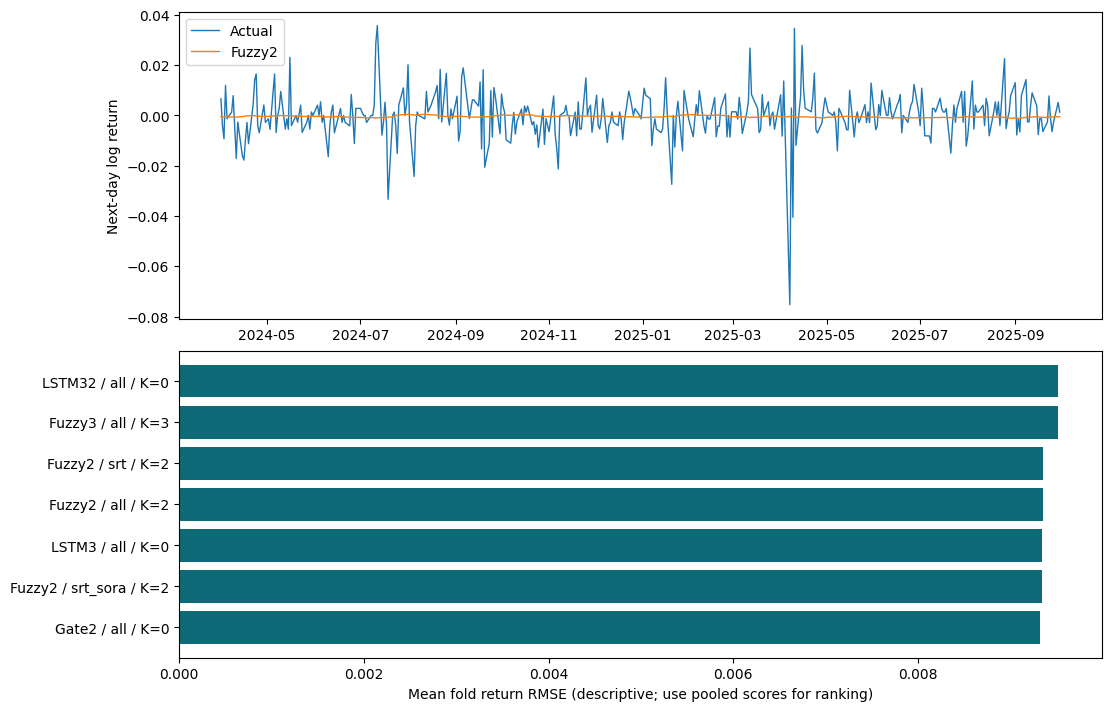

In [9]:
if model_predictions is not None:
    joined = data.validate_predictions(model_predictions)
    primary = joined.loc[
        (joined.model_id == "Fuzzy2") & (joined.source_group == "all")
        & (joined.seed == 11) & (joined.fold != "final_holdout")
    ].sort_values("target_date")
    if len(primary):
        fig, axes = plt.subplots(2, 1, figsize=(11, 7), constrained_layout=True)
        axes[0].plot(primary.target_date, primary.y_true, label="Actual", linewidth=1)
        axes[0].plot(primary.target_date, primary.y_pred, label="Fuzzy2", linewidth=1)
        axes[0].set_ylabel("Next-day log return")
        axes[0].legend()
        overview = model_scores.loc[model_scores.fold != "final_holdout"].groupby(
            ["model_id", "source_group", "rule_count"], as_index=False
        ).return_rmse.mean().sort_values("return_rmse")
        labels = overview.model_id + " / " + overview.source_group + " / K=" + overview.rule_count.astype(str)
        axes[1].barh(labels, overview.return_rmse, color="#0c6b76")
        axes[1].set_xlabel("Mean fold return RMSE (descriptive; use pooled scores for ranking)")
        plt.show()
    else:
        print("Awaiting full-feature Fuzzy2, seed 11, for the forecast plot.")

## Fuzzy-rule diagnostics

Protocol v1.2 requires a case table with the full `(model_id,source_group,rule_count,fold,seed,window_id)` key and `z1,z2,z3,y_mix_raw`, plus a rule-long table with that key and `rule_id,alpha,expert_raw,log_membership,distance2`. The validator checks one case and exactly `rule_count` rule rows per fuzzy forecast, including the raw-return weighted-mixture identity. The saved training-cut local-error analysis appears below; rule-number switching across seeds limits semantic labels.

In [10]:
case_file = Path("output/development/cases.csv")
rule_file = Path("output/development/rules.csv")
if case_file.exists() and rule_file.exists() and model_predictions is not None:
    fuzzy_cases, fuzzy_rules = data.validate_fuzzy_diagnostics(
        model_predictions, pd.read_csv(case_file), pd.read_csv(rule_file))
    print("Validated fuzzy cases:", len(fuzzy_cases), "rule rows:", len(fuzzy_rules))
    display(fuzzy_rules.groupby(["model_id", "source_group", "rule_count", "rule_id"]).alpha.agg(["count", "mean", "min", "max"]))
elif case_file.exists() or rule_file.exists():
    print("Both fuzzy diagnostic files and the prediction file are required for validation.")
else:
    print(f"Awaiting fuzzy diagnostics: {case_file} and {rule_file}")

Validated fuzzy cases: 3780 rule rows: 7938


count      mean       min       max
model_id source_group rule_count rule_id                                     
Fuzzy2   all          2          1         1134  0.475873  0.418999  0.533680
                                 2         1134  0.524127  0.466320  0.581001
         srt          2          1         1134  0.472719  0.406548  0.502466
                                 2         1134  0.527281  0.497534  0.593452
         srt_sora     2          1         1134  0.513117  0.459579  0.594684
                                 2         1134  0.486883  0.405316  0.540421
Fuzzy3   all          3          1          378  0.309397  0.278245  0.324835
                                 2          378  0.353446  0.337667  0.371527
                                 3          378  0.337157  0.322116  0.354225

## Portfolio application — causal observed-open ledger

A signal formed after close `t` is first executable at the next SRT open. The realized open-to-open interval differs from the close-to-close forecast label. The ledger trades only at observed opens, carries shares/cash across a missing opening quote and liquidates at the known fold boundary. It records model signals, a model-free five-day momentum signal, always-long and always-cash on identical dates. Costs are 10 basis points per side here. The nine SRT distribution events have issuer corroboration in `docs/srt_distribution_source_audit.md`; show gross-distribution and price-only wealth separately. The 2025-10-24 open remains missing, so any final-period trade path must be labelled a constrained-data simulation.

,fold,strategy,terminal_wealth_multiple,max_drawdown,one_way_trade_count
0,validation_1,signal_long_cash,1.000000,0.000000,0
1,validation_1,momentum_long_cash,0.983848,0.104137,32
2,validation_1,always_long,1.080731,0.080977,2
3,validation_1,always_cash,1.000000,0.000000,0
4,validation_2,signal_long_cash,1.000000,0.000000,0
5,validation_2,momentum_long_cash,1.022473,0.040463,22
6,validation_2,always_long,0.894171,0.161836,2
7,validation_2,always_cash,1.000000,0.000000,0
8,validation_3,signal_long_cash,1.000000,0.000000,0
9,validation_3,momentum_long_cash,1.044118,0.043192,18


,fold,strategy,terminal_wealth_multiple,distribution_cash_sgd_per_initial_sgd
0,validation_1,signal_long_cash,1.000000,0.000000
1,validation_1,momentum_long_cash,1.011773,0.027357
2,validation_1,always_long,1.109650,0.028918
3,validation_1,always_cash,1.000000,0.000000
4,validation_2,signal_long_cash,1.000000,0.000000
5,validation_2,momentum_long_cash,1.022473,0.000000
6,validation_2,always_long,0.921072,0.026901
7,validation_2,always_cash,1.000000,0.000000
8,validation_3,signal_long_cash,1.000000,0.000000
9,validation_3,momentum_long_cash,1.074835,0.030717


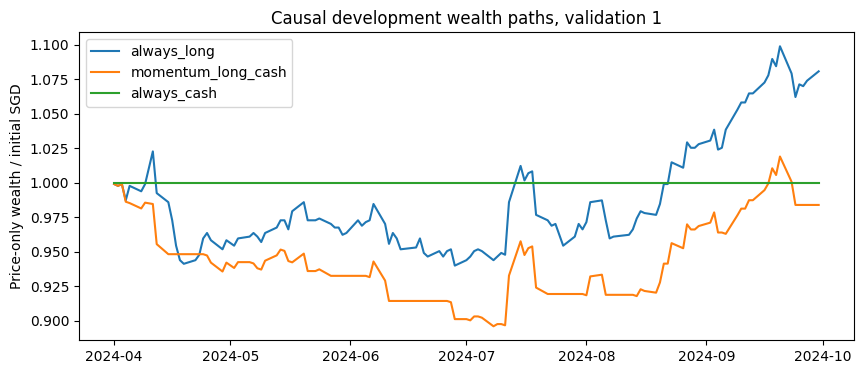

,model_id,fold,seed,terminal_wealth_multiple
0,Fuzzy2,validation_1,11,1.036177
12,Fuzzy2,validation_2,11,0.941683
24,Fuzzy2,validation_3,11,1.000000
108,Fuzzy3,validation_1,11,1.047023
112,Fuzzy3,validation_2,11,0.873209
116,Fuzzy3,validation_3,11,1.000000
120,Gate2,validation_1,11,0.996026
132,Gate2,validation_2,11,0.969097
144,Gate2,validation_3,11,1.018251
156,LSTM3,validation_1,11,1.053874


In [11]:
zero_ledger, zero_wealth = data.portfolio_ledger(zero_predictions, cost_bps=10)
_, zero_total_wealth = data.portfolio_ledger(
    zero_predictions, cost_bps=10, wealth_mode="gross_distribution")
display(zero_wealth[["fold", "strategy", "terminal_wealth_multiple",
                     "max_drawdown", "one_way_trade_count"]])
display(zero_total_wealth[["fold", "strategy", "terminal_wealth_multiple",
                           "distribution_cash_sgd_per_initial_sgd"]])
first_fold = zero_ledger.loc[zero_ledger.fold == "validation_1"]
fig, ax = plt.subplots(figsize=(10, 4))
for strategy in ("always_long", "momentum_long_cash", "always_cash"):
    path = first_fold.loc[first_fold.strategy == strategy]
    ax.plot(path.date, path.wealth, label=strategy)
ax.legend()
ax.set_ylabel("Price-only wealth / initial SGD")
ax.set_title("Causal development wealth paths, validation 1")
plt.show()
if model_predictions is not None:
    model_wealth = pd.read_csv("output/development/wealth_summary_price_only_10bps.csv")
    display(model_wealth.loc[
        model_wealth.source_group.eq("all") & model_wealth.seed.eq(11)
        & model_wealth.strategy.eq("signal_long_cash"),
        ["model_id", "fold", "seed", "terminal_wealth_multiple"]])
else:
    print("Trained-model wealth paths await complete validation predictions.")

## Development-only comparison and interpretation

These three forward validation folds were used to compare models and select the secondary trading threshold. They are **not** the reserved final test. The complete analysis and qualified conclusions are in `docs/development_results_2026-11-03.md`. In particular, the zero-return baseline currently has the lowest pooled RMSE, the untuned fuzzy strategy does not beat the model-free trading controls, and rule weights do not establish distinct economic regimes. The approved six-feature model remains the primary specification regardless of the small source-ablation differences.

In [12]:
development_dir = Path("output/development")
if (development_dir / "forecast_primary_summary.csv").exists():
    display(pd.read_csv(development_dir / "forecast_primary_summary.csv"))
    display(pd.read_csv(development_dir / "forecast_paired_fuzzy2.csv"))
    display(pd.read_csv(development_dir / "fuzzy2_source_ablation.csv"))
    display(pd.read_csv(development_dir / "rule_count_sensitivity_seed11.csv"))
    display(pd.read_csv(development_dir / "fuzzy_coverage.csv").query(
        "model_id == 'Fuzzy2' and source_group == 'all'")[[
            "fold", "seed", "mean_max_alpha", "fraction_max_alpha_gt_08",
            "fraction_below_train_support_p05"]])
    print("Frozen development threshold choices:")
    print((development_dir / "selected_policy_thresholds.json").read_text(encoding="utf-8")[:850])
else:
    print("Development comparison files are not present yet.")

,model_id,source_group,rule_count,seeds,mean_return_rmse,sd_return_rmse,mean_return_mae,mean_price_rmse_sgd,mean_direction_accuracy
0,Z0,all,0,1,0.009431,NaN,0.006290,0.006899,0.000000
1,Gate2,all,0,3,0.009456,0.000020,0.006353,0.006921,0.492711
2,LSTM3,all,0,3,0.009473,0.000025,0.006387,0.006934,0.495627
3,Fuzzy2,all,2,3,0.009489,0.000024,0.006385,0.006941,0.497570
4,Fuzzy3,all,3,1,0.009617,NaN,0.006503,0.007033,0.483965
5,LSTM32,all,0,3,0.009624,0.000147,0.006518,0.007041,0.500486


,challenger,benchmark,source_group,seed,n,challenger_rmse,benchmark_rmse,delta_rmse,delta_mae
0,Fuzzy2,LSTM32,all,11,378,0.009478,0.009457,0.000021,0.000053
1,Fuzzy2,LSTM32,all,23,378,0.009516,0.009677,-0.000161,-0.000171
2,Fuzzy2,LSTM32,all,37,378,0.009472,0.009736,-0.000264,-0.000283
3,Fuzzy2,LSTM3,all,11,378,0.009478,0.009492,-0.000015,-0.000036
4,Fuzzy2,LSTM3,all,23,378,0.009516,0.009445,0.000071,0.000057
5,Fuzzy2,LSTM3,all,37,378,0.009472,0.009481,-0.000009,-0.000029
6,Fuzzy2,Gate2,all,11,378,0.009478,0.009458,0.000020,0.000032
7,Fuzzy2,Gate2,all,23,378,0.009516,0.009475,0.000041,0.000033
8,Fuzzy2,Gate2,all,37,378,0.009472,0.009436,0.000036,0.000029


,source_group,seeds,mean_return_rmse,sd_return_rmse
0,all,3,0.009489,0.000024
1,srt,3,0.009485,0.000013
2,srt_sora,3,0.009479,0.000015


,model_id,source_group,rule_count,seed,n,return_rmse,return_mae,price_rmse_sgd,price_mae_sgd,direction_n,zero_actual_n,direction_accuracy,effective_k,k1_note
0,Fuzzy2,all,2,11,378,0.009478,0.006370,0.006932,0.004707,343,35,0.498542,2,NaN
1,Fuzzy3,all,3,11,378,0.009617,0.006503,0.007033,0.004804,343,35,0.483965,3,NaN
2,LSTM3,all,0,11,378,0.009492,0.006405,0.006951,0.004736,343,35,0.489796,1,LSTM3 is functionally Fuzzy1


,fold,seed,mean_max_alpha,fraction_max_alpha_gt_08,fraction_below_train_support_p05
0,validation_1,11,0.558540,0.0,0.007937
1,validation_1,23,0.536319,0.0,0.039683
2,validation_1,37,0.510615,0.0,0.031746
10,validation_2,11,0.557251,0.0,0.000000
11,validation_2,23,0.525095,0.0,0.000000
12,validation_2,37,0.510154,0.0,0.000000
20,validation_3,11,0.558571,0.0,0.023438
21,validation_3,23,0.519579,0.0,0.203125
22,validation_3,37,0.517218,0.0,0.156250


Frozen development threshold choices:
{
  "status": "frozen_from_development_only",
  "source_group": "all",
  "wealth_mode": "price_only",
  "cost_bps": 10,
  "theta_grid": [
    0.0,
    0.001,
    0.002,
    0.003
  ],
  "tie_break": "smaller theta",
  "objective": "mean across seeds of sum across folds of log terminal wealth",
  "selected": {
    "Fuzzy2": 0.002,
    "Gate2": 0.001,
    "LSTM3": 0.002,
    "LSTM32": 0.003,
    "momentum_long_cash": 0.0
  },
  "objectives": [
    {
      "policy": "Fuzzy2",
      "theta": 0.0,
      "mean_sum_fold_log_wealth": -0.02541255175748956
    },
    {
      "policy": "Fuzzy2",
      "theta": 0.001,
      "mean_sum_fold_log_wealth": -0.0016885054999809179
    },
    {
      "policy": "Fuzzy2",
      "theta": 0.002,
      "mean_sum_fold_log_wealth": 0.0
    },
    {
      "policy": "Fuzzy2",
      "theta": 0.003,
      "mean_sum_fol


## Frozen final evaluation and course conclusion

The next cells read `output/final/`. The 931/251 train/test split, four models, three seeds, fixed final epochs, baselines and policies were frozen before these 251 targets were scored. All final model predictions were generated once. A control-table error occurred after those predictions had been saved; the analysis resumed from the identical files without a second fit. The execution records and hashes preserve that sequence.

### Executable model and training interface

`src/models.py` contains the 32-unit LSTM encoder, compact 3D projection, two diagonal-Gaussian antecedents and affine experts. For `Fuzzy2`, `z∈R³`, `αₖ=softmax(-dₖ²/2)`, and `ŷ=Σₖαₖeₖ(z)`. The centers start at `(-0.25,0,0)` and `(0.25,0,0)`; there is no K-means initialization or auxiliary clustering loss. `src/train.py` trains standardized returns with AdamW, global MSE, chronological inner stopping and same-seed outer refit. Final refit epochs are fixed medians of the nine development best epochs, not chosen from final labels.

To reproduce training from scratch in a **new** directory, use `python -m src.tools.run_development_matrix --include-gate --device cpu --out output/runs/reproduction/development`, then the commands in `docs/README_DESTIN_HANDOFF.md`. The once-only final exports are already stored; this Notebook performs read-only final analysis.

In [13]:
from src.models import build_model, parameter_count
from src.tools.run_final_holdout import preflight
frozen, _ = preflight()
model_sizes = pd.DataFrame([
    {"model": name, "parameters": parameter_count(build_model(name, 6)),
     "final_fixed_epochs": frozen["final_refit_epochs_by_model"][name]}
    for name in frozen["final_models"]
])
display(model_sizes)
print("Final train/test windows:", frozen["final_train_windows"], frozen["final_eval_windows"])

,model,parameters,final_fixed_epochs
0,LSTM32,5153,1
1,LSTM3,5223,6
2,Fuzzy2,5239,3
3,Gate2,5241,4


Final train/test windows: 931 251


### Final forecasting result

The primary metric is raw next-close log-return RMSE. `Z0` predicts zero return, equivalent to an unchanged closing price. Final `Fuzzy2` RMSE is 0.006349, about 0.44% below `Z0` and 0.55% below ordinary `LSTM32`; the absolute margins are small. `Z0` has the best MAE. The three seeds share one 251-day test period, so seed spread is not a cross-market uncertainty interval. The mechanical zero directional accuracy exported for `Z0` is not an informative directional benchmark.

,model_id,seeds,return_rmse_mean,return_rmse_sd,return_mae_mean,price_rmse_sgd_mean,direction_accuracy_mean
0,Fuzzy2,3,0.006349,0.000011,0.004595,0.004782,0.490455
1,Gate2,3,0.006353,0.000005,0.004582,0.004786,0.493392
2,LSTM3,3,0.006355,0.000004,0.004593,0.004787,0.474302
3,Z0,1,0.006377,NaN,0.004547,0.004803,0.000000
4,LSTM32,3,0.006384,0.000031,0.004651,0.004809,0.474302


,seed,challenger,benchmark,delta_rmse,delta_mae
0,11,Fuzzy2,LSTM32,-0.000029,0.000002
1,11,Fuzzy2,LSTM3,-0.000007,-0.000013
2,11,Fuzzy2,Gate2,-0.000004,-0.000012
3,23,Fuzzy2,LSTM32,-0.000018,-0.000060
4,23,Fuzzy2,LSTM3,-0.000015,0.000043
5,23,Fuzzy2,Gate2,-0.000015,0.000044
6,37,Fuzzy2,LSTM32,-0.000059,-0.000111
7,37,Fuzzy2,LSTM3,0.000004,-0.000025
8,37,Fuzzy2,Gate2,0.000006,0.000006


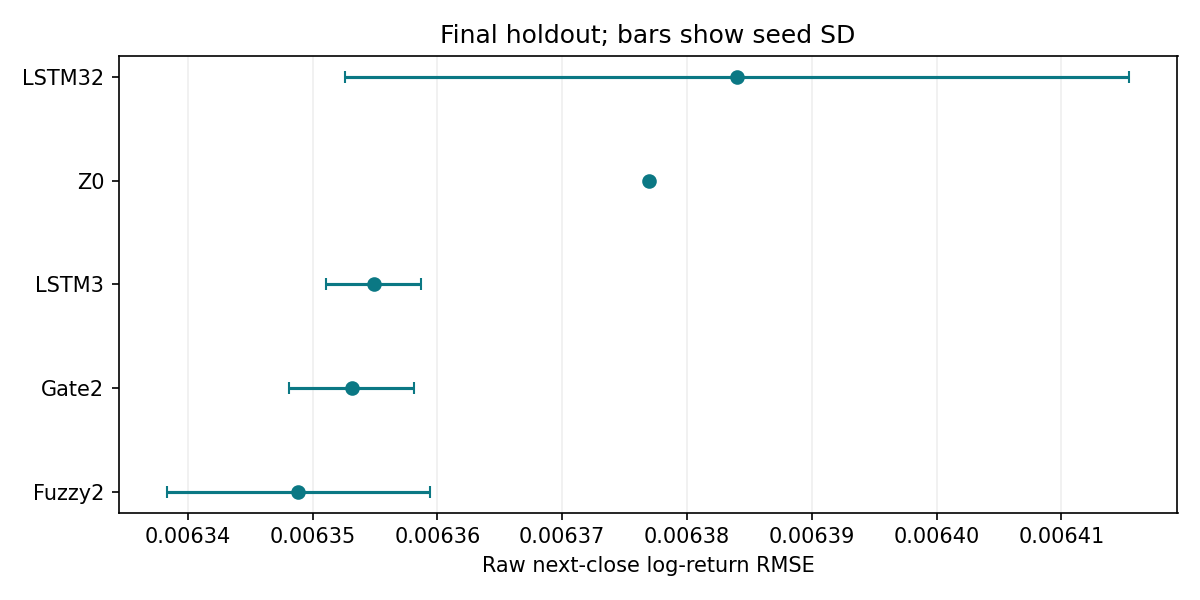

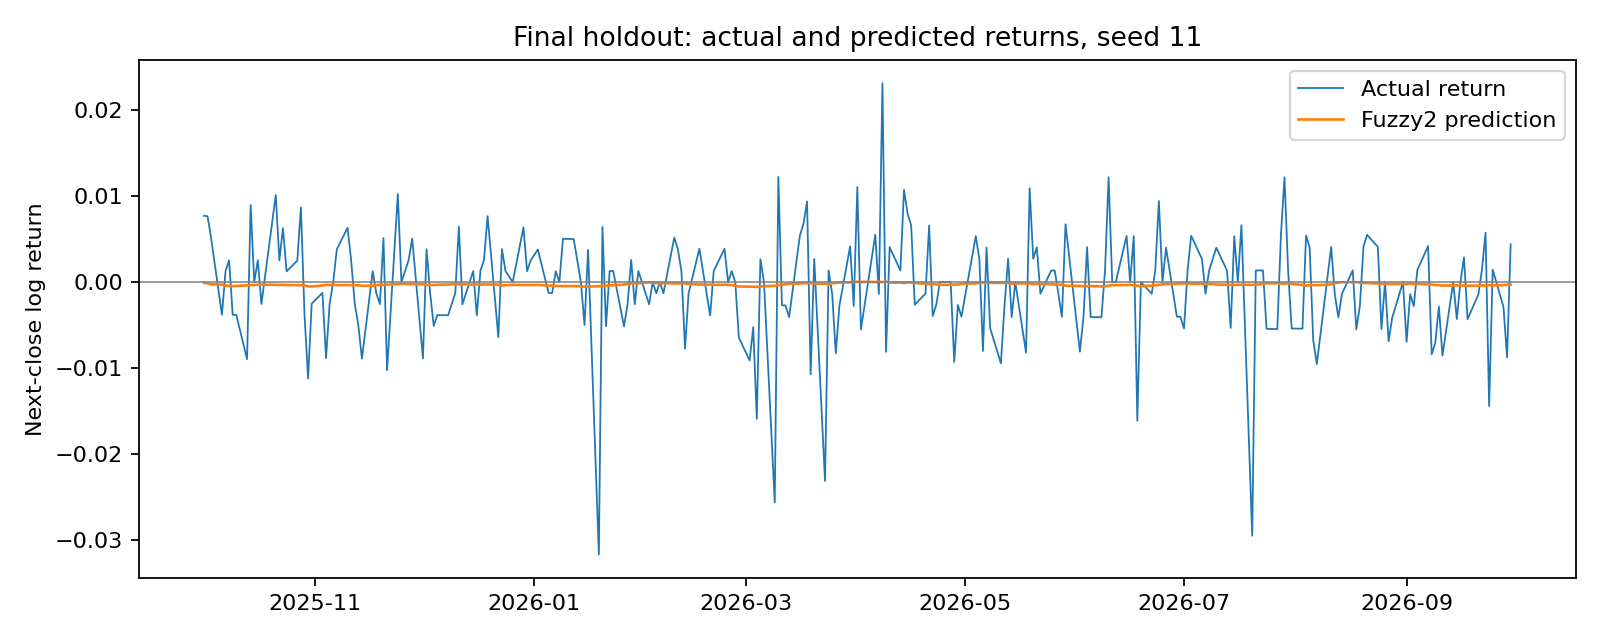

In [14]:
from IPython.display import Image
final_dir = Path("output/final")
subprocess.run([sys.executable, "-m", "src.tools.verify_final_outputs"], check=True)
display(pd.read_csv(final_dir / "forecast_summary.csv"))
display(pd.read_csv(final_dir / "forecast_paired_fuzzy2.csv"))
display(Image(filename=str(final_dir / "forecast_rmse.png")))
display(Image(filename=str(final_dir / "prediction_vs_actual_seed11.png")))

### Why trading almost never occurred

The primary policy enters at the next observed SRT open only when the return prediction exceeds zero, with 10 bps cost per side. `Fuzzy2` predicts a narrow range around zero: seed 11 is positive on six of 251 target days; seeds 23 and 37 are never positive. The latter two policies remain in cash. The development-selected secondary thresholds make **all 12** final model-seed policies stay in cash; that is a sensitivity result, not successful trading. The single missing 2025-10-24 open uses the frozen no-trade-and-carry rule.

,seed,predicted_mean,predicted_sd,predicted_min,predicted_max,positive_count,n,positive_fraction
0,11,-0.000273,0.000133,-0.000555,0.000075,6,251,0.023904
1,23,-0.000653,0.000160,-0.001017,-0.000160,0,251,0.000000
2,37,-0.000311,0.000061,-0.000513,-0.000149,0,251,0.000000


,seed,observed_opens,invested_opens,terminal_wealth_multiple,one_way_trade_count
0,11,250,6,0.997514,4
1,23,250,0,1.000000,0
2,37,250,0,1.000000,0


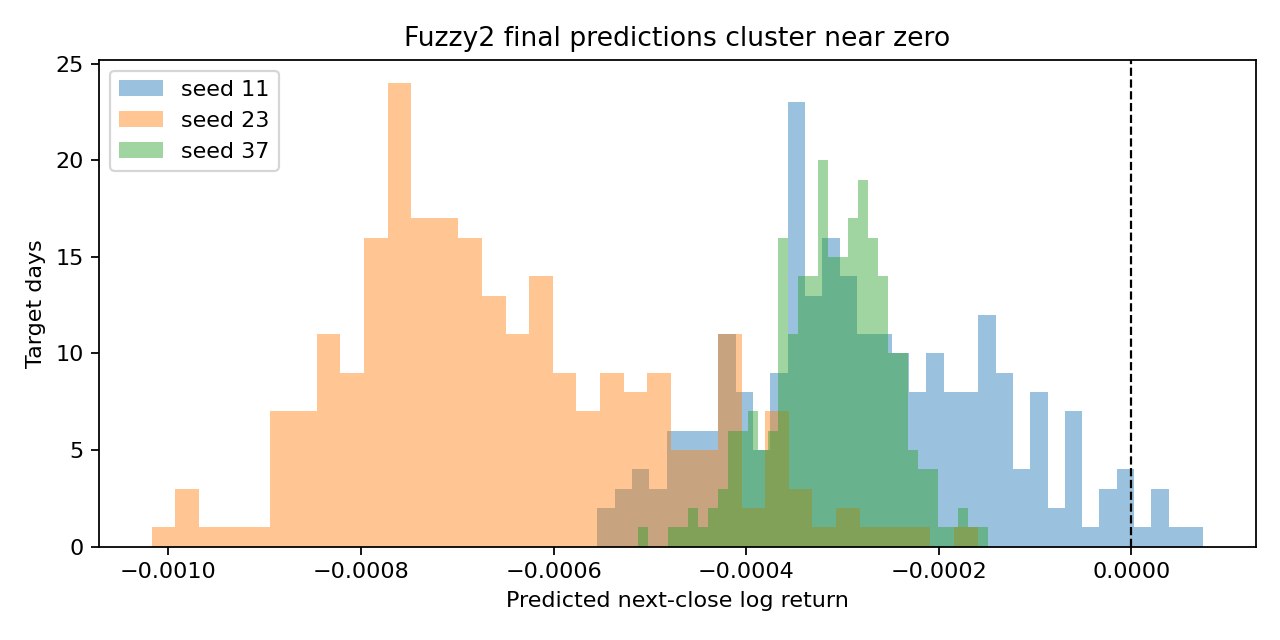

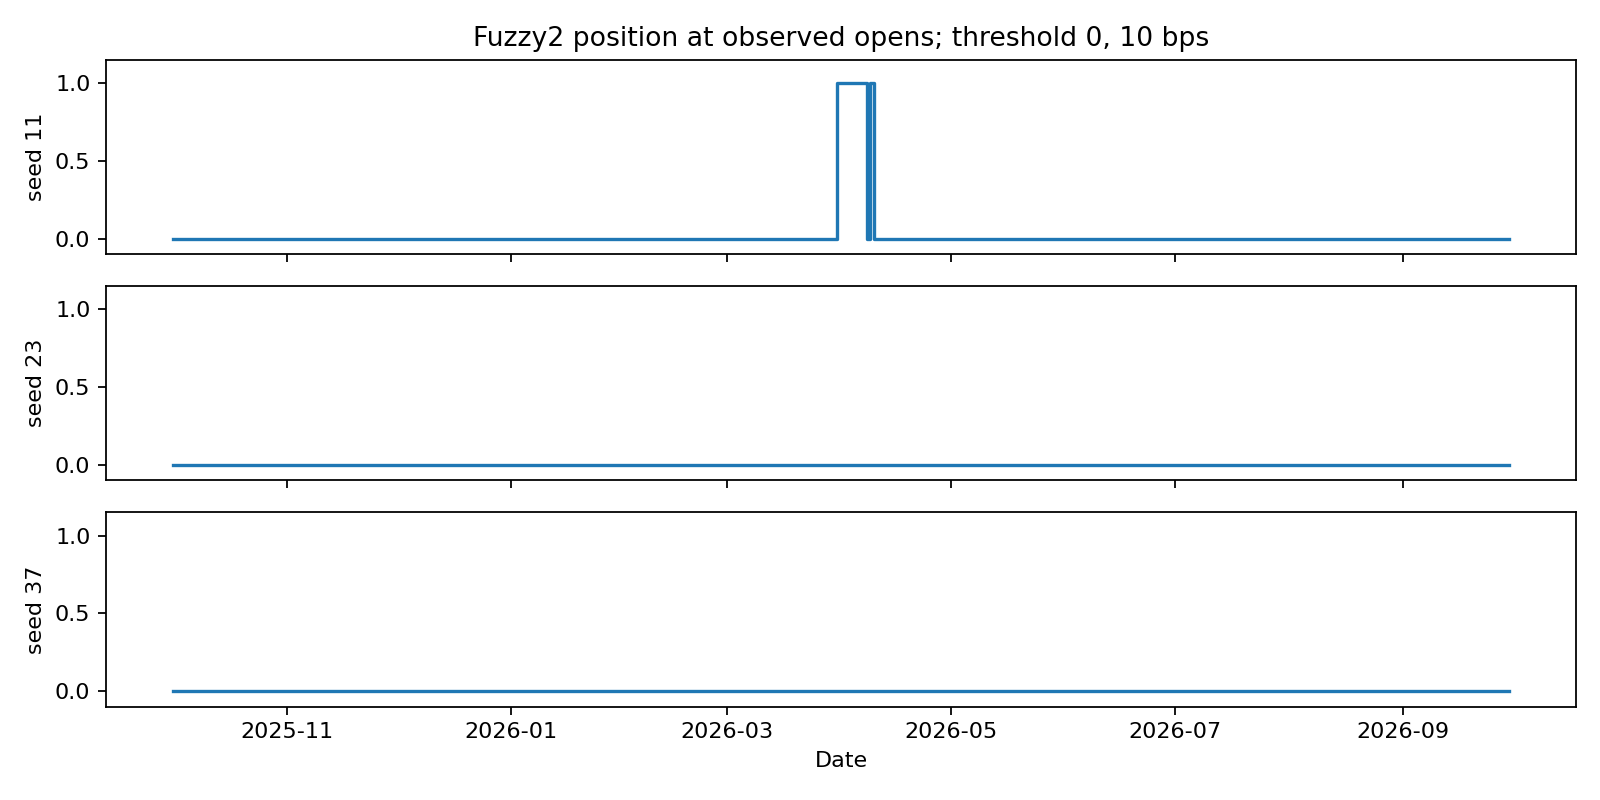

,wealth_mode,cost_bps_per_side,model_id,seeds,terminal_wealth_mean,terminal_wealth_sd,drawdown_mean,trades_mean
16,price_only,10,Fuzzy2,3,0.999171,0.001436,0.003692,1.333333
17,price_only,10,Gate2,3,0.969583,0.028038,0.045027,24.000000
18,price_only,10,LSTM3,3,0.983927,0.011943,0.033748,12.666667
19,price_only,10,LSTM32,3,0.963191,0.063756,0.037633,13.333333
20,price_only,10,Z0,1,1.000000,NaN,0.000000,0.000000
21,price_only,10,always_cash,0,1.000000,NaN,0.000000,0.000000
22,price_only,10,always_long,0,0.878242,NaN,0.158867,2.000000
23,price_only,10,momentum_long_cash,0,0.924490,NaN,0.091030,38.000000


,model_id,seed,threshold,terminal_wealth_multiple,one_way_trade_count
0,LSTM32,11,0.003,1.0,0
1,LSTM32,23,0.003,1.0,0
2,LSTM32,37,0.003,1.0,0
3,LSTM3,11,0.002,1.0,0
4,LSTM3,23,0.002,1.0,0
5,LSTM3,37,0.002,1.0,0
6,Fuzzy2,11,0.002,1.0,0
7,Fuzzy2,23,0.002,1.0,0
8,Fuzzy2,37,0.002,1.0,0
9,Gate2,11,0.001,1.0,0


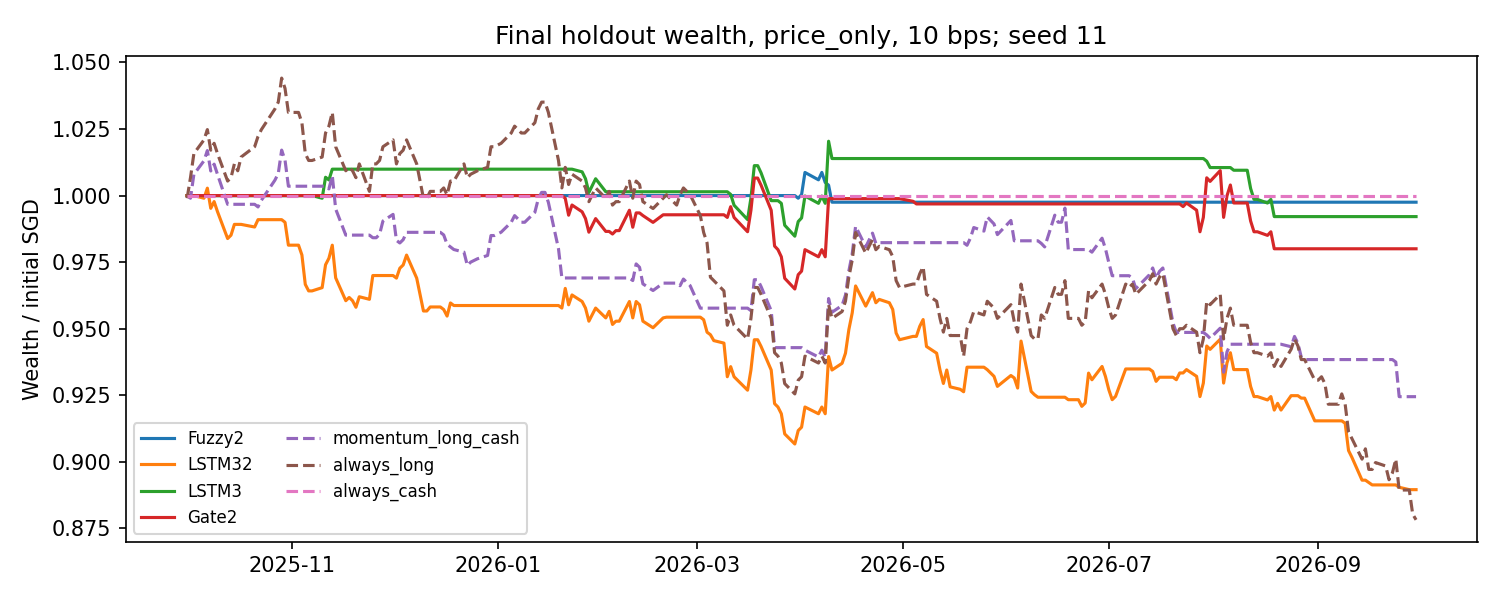

In [15]:
display(pd.read_csv(final_dir / "fuzzy_prediction_distribution.csv"))
display(pd.read_csv(final_dir / "fuzzy_position_summary.csv"))
display(Image(filename=str(final_dir / "fuzzy_prediction_distribution.png")))
display(Image(filename=str(final_dir / "fuzzy_positions_by_seed.png")))
primary_wealth = pd.read_csv(final_dir / "wealth_comparison.csv")
display(primary_wealth.query("wealth_mode == 'price_only' and cost_bps_per_side == 10"))
display(pd.read_csv(final_dir / "wealth_selected_threshold_10bps.csv")[[
    "model_id", "seed", "threshold", "terminal_wealth_multiple", "one_way_trade_count"]])
display(Image(filename=str(final_dir / "wealth_paths_price_only_10bps.png")))

### Rule behavior and local evidence

The fuzzy case/rule tables satisfy the weighted-mixture identity. Final maximum rule weights average only 0.511–0.563, with no case above 0.8; one rule has no cases above its **training-defined** high-activation cut in one seed. Rule contributions are inspectable, but rule index 1 or 2 does not have a stable bull/bear meaning. The examples below were chosen *after* evaluation for explanation only (largest absolute forecast, largest absolute error, strongest weight); they were not used to select models or policies.

,model_id,source_group,rule_count,fold,seed,rule_id,n,alpha_train_q75,high_activation_n,mean_max_alpha,fraction_max_alpha_gt_08,support_train_p05,fraction_below_train_support_p05,activated_expert_mae,other_expert_mae,mixture_mae_same_rows
0,Fuzzy2,all,2,final_holdout,11,1,251,0.442981,12,0.562888,0.0,-0.131253,0.0,0.007619,0.005298,0.004974
1,Fuzzy2,all,2,final_holdout,11,2,251,0.564142,90,0.562888,0.0,-0.131253,0.0,0.005475,0.006160,0.004592
2,Fuzzy2,all,2,final_holdout,23,1,251,0.469168,146,0.530196,0.0,-0.089295,0.0,0.004978,0.005190,0.004793
3,Fuzzy2,all,2,final_holdout,23,2,251,0.546366,2,0.530196,0.0,-0.089295,0.0,0.002244,0.006032,0.003953
4,Fuzzy2,all,2,final_holdout,37,1,251,0.512230,85,0.511433,0.0,-0.054130,0.0,0.004925,0.005146,0.004675
5,Fuzzy2,all,2,final_holdout,37,2,251,0.495822,0,0.511433,0.0,-0.054130,0.0,NaN,NaN,NaN


,selection_reason_descriptive_only,target_date,window_id,y_true,y_pred,absolute_error,alpha_1,alpha_2,expert_raw_1,expert_raw_2,contribution_1,contribution_2
0,largest_abs_prediction,2026-03-04,1036,-0.015894,-0.000555,0.015340,0.440637,0.559363,-0.004993,0.002942,-0.002200,0.001646
1,largest_abs_error,2026-01-19,1006,-0.031668,-0.000477,0.031191,0.444389,0.555611,-0.004821,0.002998,-0.002142,0.001666
2,strongest_rule_weight,2026-03-25,1051,-0.001375,-0.000143,0.001232,0.428838,0.571162,-0.005131,0.003602,-0.002200,0.002057


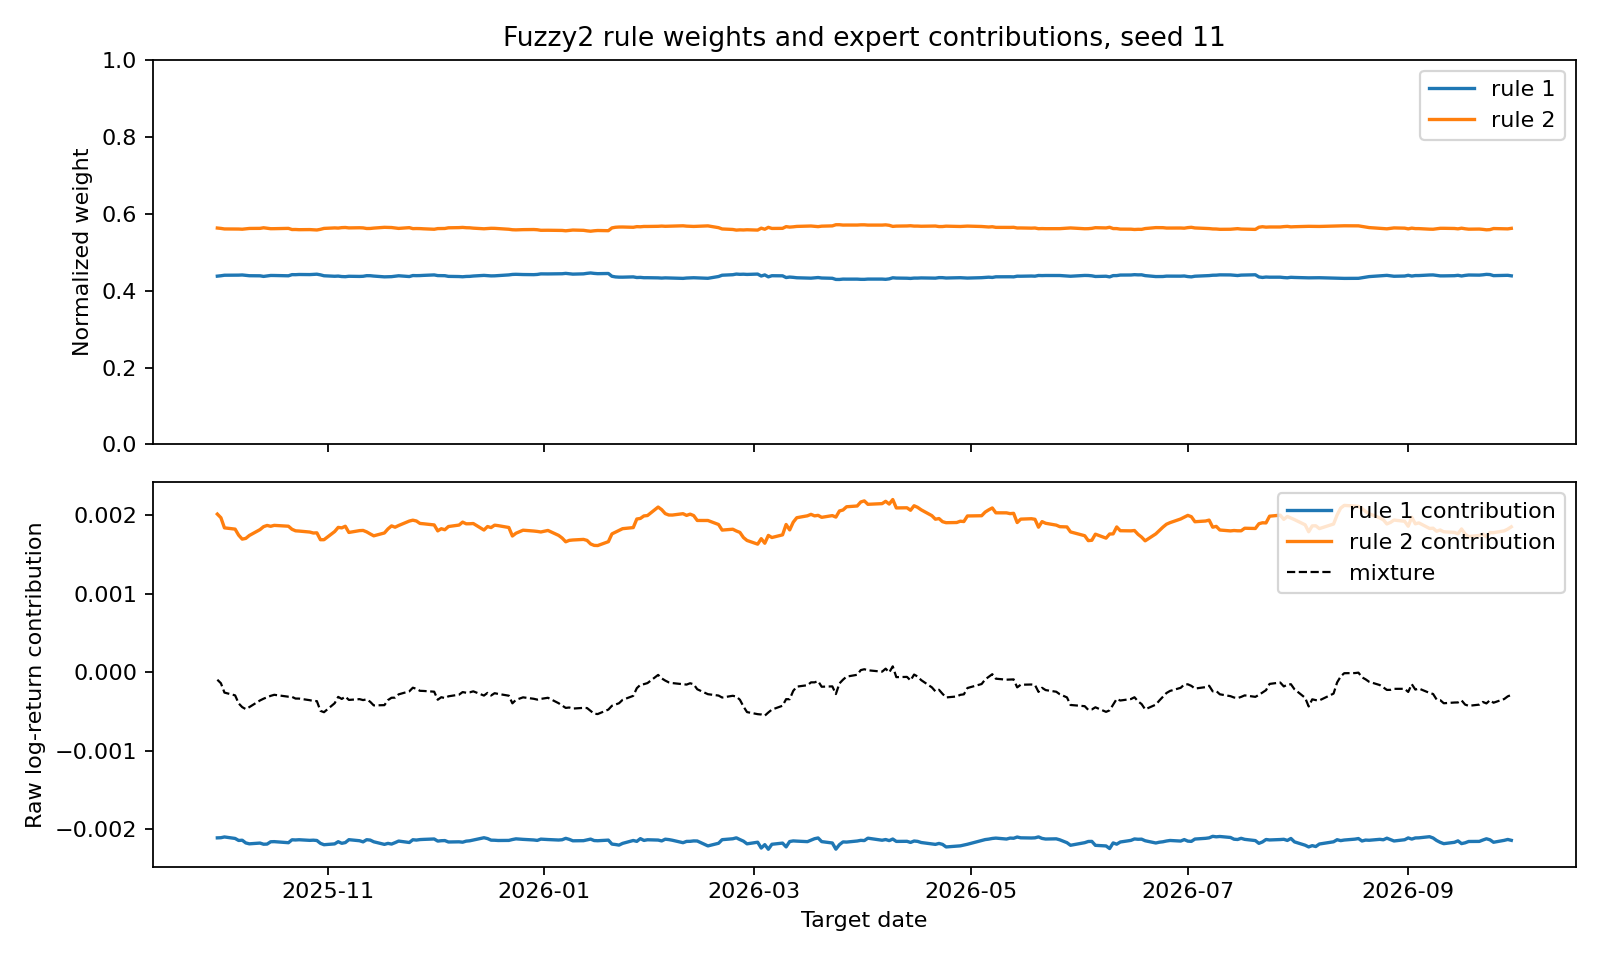

In [16]:
final_predictions = pd.read_csv(final_dir / "predictions.csv")
final_cases = pd.read_csv(final_dir / "cases.csv")
final_rules = pd.read_csv(final_dir / "rules.csv")
data.validate_fuzzy_diagnostics(final_predictions, final_cases, final_rules)
display(pd.read_csv(final_dir / "fuzzy_local_checks.csv"))
display(pd.read_csv(final_dir / "fuzzy_case_examples_seed11.csv"))
display(Image(filename=str(final_dir / "fuzzy_rules_contributions_seed11.png")))

### Training choice, input sources and rule count

The curves below show **inner development stopping** for seed 11, not final-test fitting. The final epochs (1/6/3/4) are the predeclared nine-run medians for `LSTM32`/`LSTM3`/`Fuzzy2`/`Gate2`. Early stopping may reflect weak signal and noisy short history; it does not by itself prove a training bug or sufficient convergence. In development, adding SORA or STI changed `Fuzzy2` RMSE only slightly. The seed-11 K=1/2/3 diagnostic favored K=2 over K=3, but it did not support a broad rule-count claim.

,source_group,seeds,mean_return_rmse,sd_return_rmse
0,all,3,0.009489,0.000024
1,srt,3,0.009485,0.000013
2,srt_sora,3,0.009479,0.000015


,model_id,effective_k,return_rmse
0,Fuzzy2,2,0.009478
1,Fuzzy3,3,0.009617
2,LSTM3,1,0.009492


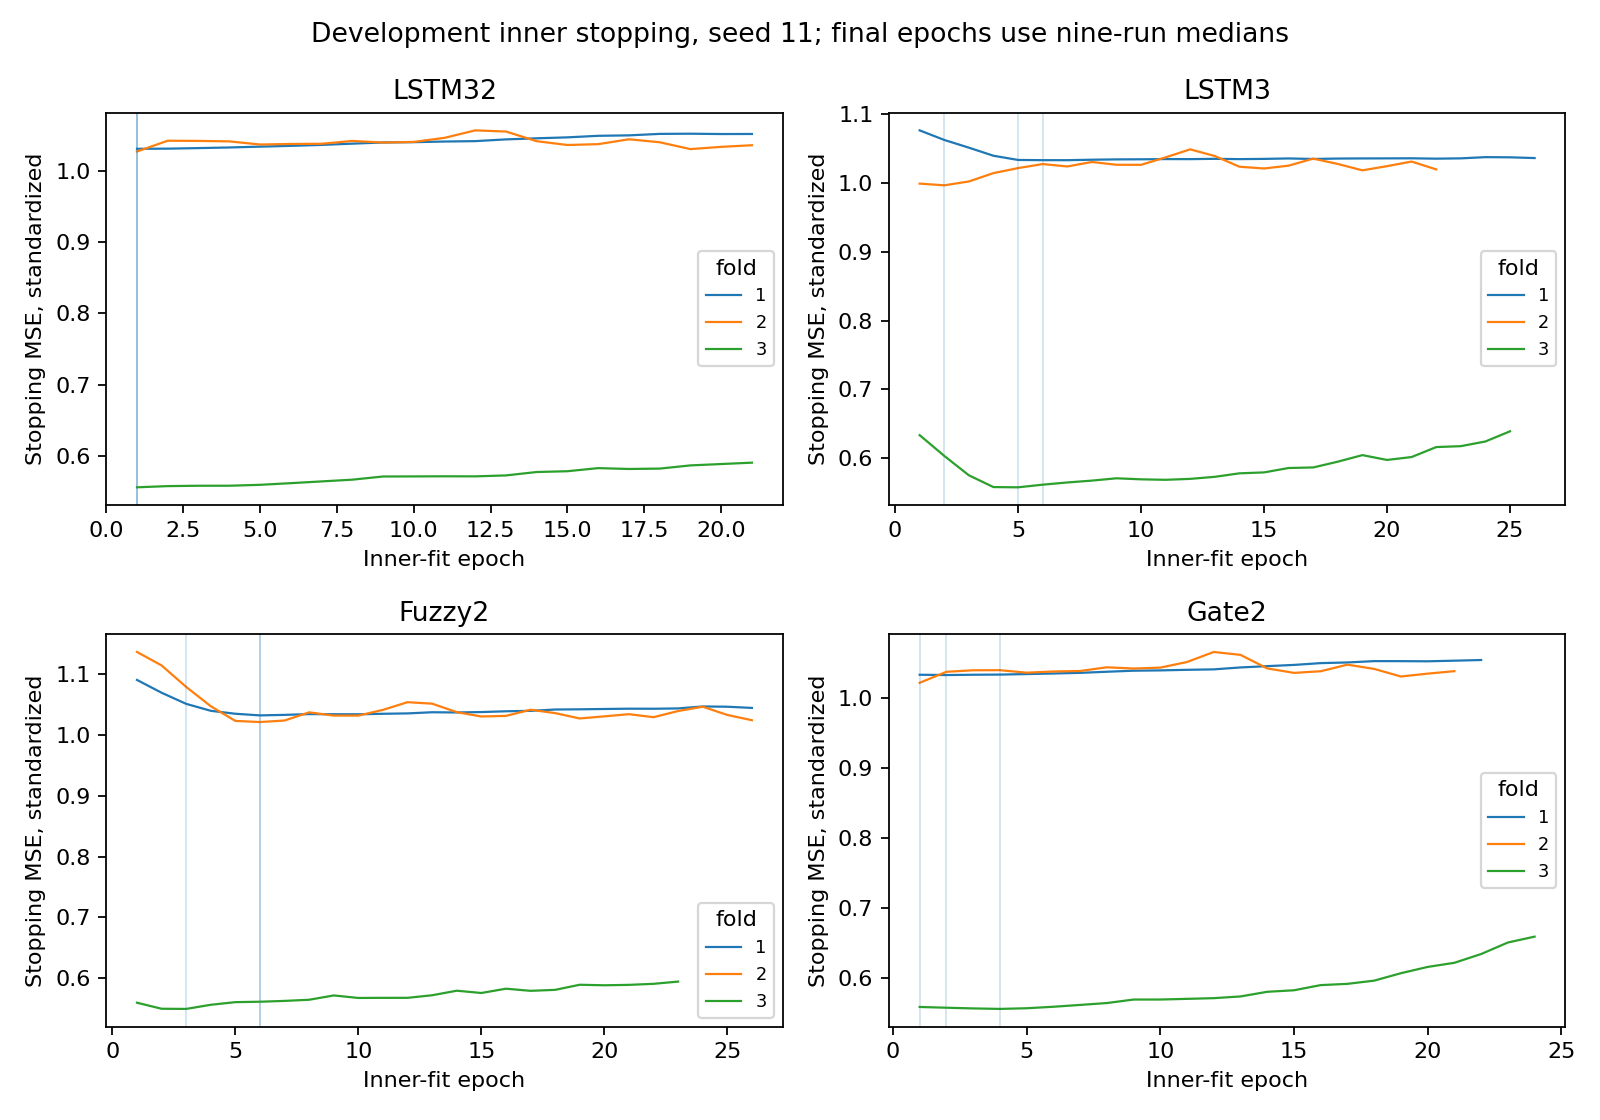

In [17]:
display(pd.read_csv(development_dir / "fuzzy2_source_ablation.csv"))
display(pd.read_csv(development_dir / "rule_count_sensitivity_seed11.csv")[[
    "model_id", "effective_k", "return_rmse"]])
display(Image(filename=str(final_dir / "development_inner_stopping.png")))

### Conclusion and limitations

The simplified LSTM→3D→two-rule fuzzy mixture achieved a **small, metric-dependent** final RMSE advantage over the ordinary LSTM and unchanged-price reference. It did not improve MAE over the reference, did not beat cash after trading costs, and did not produce clear market-regime specialists. Its near-zero, mostly negative predictions explain much of the trading result. The executable next-open return also differs from the next-close forecast target; the 248-date horizon check is in `output/final/three_return_horizon_correlations.csv`.

This test covers one ETF and one future period. The 2025-10-24 opening quote is unavailable, so trading paths are constrained-data simulations. The full issuer-verified table has nine distribution events; **two** fall inside the final holdout, and price-only and gross-distribution wealth are reported separately. Gross receipts are not investor-specific after-tax returns. This frozen test cannot be used to tune another model. Future research should test local objectives that prevent empty rules, the stability of learned rule semantics across refits, and concept drift on new periods or instruments. A building-load application and its chronological test design are specified in the literature section above.